# 14 · Ruptura de $P(Y\mid X)$ sem drift de entradas

**Pergunta didática:** um monitor de PSI pode ficar silencioso quando o risco real muda? Sim. Este ensaio hipotético mantém exatamente os mesmos registros de $X$, scores e decisões do holdout e altera **somente desfechos simulados** em segmentos definidos previamente por $X$. Portanto o PSI de todas as entradas e do score é exatamente zero. As métricas abaixo são **simulações de cenário**, não estimativas observadas de produção.

**Fonte de ideias:** monitoramento do desempenho após chegada de rótulos e limites do covariate shift em [BoE SS1/23, §§3.3 e 4.4](https://www.bankofengland.co.uk/-/media/boe/files/prudential-regulation/supervisory-statement/2023/ss123.pdf), MRMIA *Machine Learning and Model Risk Management* (2021, pp. 28–35 do PDF) e van Breugel et al. (2023, *3S Testing*, pp. 5–6 e 28–29 do PDF). O mecanismo de troca de rótulos é **construção nossa**, não procedimento atribuído a essas obras.

**Roteiro:** (1) carregar o Booster congelado com peso 13,882494684620836 e corte 0,50; (2) definir grupos apenas com quantis do treino; (3) converter de 5% em 5%, até 50%, dos não eventos observados em eventos *hipotéticos*; (4) comparar AUC ROC, PR-AUC trapezoidal, KS do modelo, Brier e prevalência mantendo $X$ e scores fixos; (5) consultar recall e precisão no corte como referências; (6) discutir o que só dados futuros rotulados podem confirmar. Todos os níveis são executados; não há critério de parada.

> Nunca usar estes rótulos simulados como verdade empírica. Também não devemos interpretar um `classification_report` contra rótulos aleatórios como evidência de desempenho.


In [1]:
from pathlib import Path

# Resolve o projeto tanto pelo Jupyter aberto em notebooks/ quanto pelo executor.
_inicio = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in (_inicio, *_inicio.parents)
     if (p / "models" / "manifesto_modelo.json").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Não encontrei models/manifesto_modelo.json. Abra o projeto clonado.")
DATA_DIR_PROJECT = PROJECT_ROOT / "data" / "raw"
MODEL_DIR = PROJECT_ROOT / "models"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
for _nome in ("cs-training.csv", "cs-test.csv"):
    if not (DATA_DIR_PROJECT / _nome).is_file():
        raise FileNotFoundError(
            f"Falta {DATA_DIR_PROJECT / _nome}. Veja README.md, seção Dados."
        )


## 1. Dados, modelo, proveniência e linha de base

O primeiro `train_test_split(test_size=0.15, random_state=33)` de `model_final.ipynb` define 22.500 casos de holdout. O segundo split é refeito para obter cortes de segmentos apenas do treino original. O modelo não é reajustado. Conferimos hash do JSON, peso solicitado e corte no manifesto. AUC ROC mede a ordenação de positivos versus negativos. PR-AUC trapezoidal é `auc(recall_curve, precision_curve)`; AP é outro resumo dessa curva e aparece só como complemento. KS do modelo é $\max_t[TPR(t)-FPR(t)]$ ao longo dos limiares da curva ROC, e **não** é KS de drift entre entradas. Brier é a média de $(y_i-p_i)^2$; recall e precisão usam $\hat y_i=\mathbb{1}(p_i\geq0,50)$. Aqui $y_i$ é desfecho e $p_i$ é score entre 0 e 1. AUC, PR-AUC e KS maiores e Brier menor indicam melhor resultado descritivo. As definições seguem a documentação do scikit-learn: [PR curve](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_curve.html), [área trapezoidal](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.auc.html), [AP](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html), [ROC curve](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_curve.html) e [Brier](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.brier_score_loss.html).


In [2]:
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             confusion_matrix, precision_recall_curve, roc_curve, auc)
from IPython.display import display

P = DATA_DIR_PROJECT
OUT = TABLES_DIR
DATA = DATA_DIR_PROJECT
manifesto = json.loads((MODEL_DIR / 'manifesto_modelo.json').read_text(encoding='utf-8'))
assert np.isclose(manifesto['params_fornecidos']['scale_pos_weight'], 13.882494684620836)
assert manifesto['cutoff'] == .50
model_path = MODEL_DIR / 'model_class_retreinado.json'
sha = hashlib.sha256(model_path.read_bytes()).hexdigest()
assert sha == manifesto['model_sha256'], 'Booster diferente do manifesto.'
features = manifesto['features']
df = pd.read_csv(DATA / 'cs-training.csv').drop(columns=['Unnamed: 0'])
target = manifesto['target']
X, y = df[features], df[target].astype(int)
X_tv, X_h, y_tv, y_h = train_test_split(X, y, test_size=.15, random_state=33)
X_t, X_v, y_t, y_v = train_test_split(X_tv, y_tv, test_size=.1765, random_state=33)
model = xgb.Booster(model_file=str(model_path))
p = model.predict(xgb.DMatrix(X_h, feature_names=features, enable_categorical=True))
y0 = y_h.to_numpy(dtype=int)
assert len(y0) == 22500

def metricas(yy, pp=p):
    tn, fp, fn, tp = confusion_matrix(yy, pp >= .50, labels=[0, 1]).ravel()
    precisao_curva, recall_curva, _ = precision_recall_curve(yy, pp)
    fpr_curva, tpr_curva, _ = roc_curve(yy, pp, drop_intermediate=False)
    return dict(prevalencia=yy.mean(), auc_roc=roc_auc_score(yy, pp),
                pr_auc_trap=auc(recall_curva, precisao_curva),
                ks_modelo=float(np.max(tpr_curva-fpr_curva)),
                ap=average_precision_score(yy, pp), brier=brier_score_loss(yy, pp),
                recall=tp/(tp+fn), precisao=tp/(tp+fp) if tp+fp else np.nan,
                fpr=fp/(fp+tn), taxa_decisao_positiva=(pp>=.50).mean())

base = metricas(y0)
for chave in ['auc_roc', 'pr_auc_trap', 'ks_modelo', 'brier', 'ap']:
    assert np.isclose(base[chave], manifesto['baseline_holdout'][chave], atol=1e-6, rtol=0), chave
print('Modelo:', model_path.name, '| árvores:', model.num_boosted_rounds(),
      '| peso:', manifesto['params_fornecidos']['scale_pos_weight'], '| corte: 0,50')
display(pd.DataFrame([base], index=['holdout observado']).round(5))

Modelo: model_class_retreinado.json | árvores: 103 | peso: 13.882494684620836 | corte: 0,50


,prevalencia,auc_roc,pr_auc_trap,ks_modelo,ap,brier,recall,precisao,fpr,taxa_decisao_positiva
holdout observado,0.06667,0.86684,0.39599,0.58771,0.39639,0.14404,0.794,0.21525,0.20676,0.24591


## 2. Cenários condicionais e fórmula

Os grupos são fixados **sem consultar o desfecho do holdout**:

* **Baixa utilização + dívida alta:** utilização até o Q25 do treino e `DebtRatio` a partir do Q75. Representa um possível fator de risco novo que o perfil histórico/score não refletia plenamente.
* **Renda baixa + utilização alta:** renda até a mediana do treino e utilização a partir do Q75. Representa aumento hipotético de eventos em um perfil já arriscado.

Para intensidade $a\in\{0,0{,}05,0{,}10,\ldots,0{,}50\}$, escolhemos de forma aninhada $\lfloor aN_{0,G}\rfloor$ registros com $Y=0$ no grupo $G$ e definimos $Y_i^{(a)}=1$. $N_{0,G}$ é o total original de não eventos elegíveis no grupo. A semente controla **quais** registros mudam; os grupos, scores e população de $X$ nunca mudam. A intensidade significa fração dos não eventos **do segmento**, não aumento relativo da prevalência global. A grade vai até 50%, sem parada por queda ou melhora de métrica.

Este experimento modifica a relação $P(Y\mid X)$; por isso sua perda ou ganho de métrica não deve ser apresentada como desempenho futuro esperado. Serve para demonstrar o limite lógico de alertas baseados apenas em entrada e score.


In [3]:
q25_util = X_t['RevolvingUtilizationOfUnsecuredLines'].quantile(.25)
q75_util = X_t['RevolvingUtilizationOfUnsecuredLines'].quantile(.75)
q75_debt = X_t['DebtRatio'].quantile(.75)
med_income = X_t['MonthlyIncome'].median()
grupos = {
    'baixa_util_divida_alta': ((X_h['RevolvingUtilizationOfUnsecuredLines'] <= q25_util) &
                               (X_h['DebtRatio'] >= q75_debt)).to_numpy(),
    'renda_baixa_util_alta': ((X_h['MonthlyIncome'] <= med_income) &
                             (X_h['RevolvingUtilizationOfUnsecuredLines'] >= q75_util)).to_numpy(),
}
display(pd.DataFrame([{'segmento':g, 'n':int(m.sum()), 'positivos_observados':int(y0[m].sum()),
                       'nao_eventos_elegiveis':int(((y0==0)&m).sum()), 'score_medio':float(p[m].mean())}
                      for g,m in grupos.items()]).round(4))
taxas = np.arange(0, 51, 5) / 100
linhas = []
for j, (nome, mascara) in enumerate(grupos.items()):
    elegiveis = np.flatnonzero(mascara & (y0 == 0))
    ordem = np.random.default_rng(20260927+j).permutation(elegiveis)
    for a in taxas:
        n_trocas = int(np.floor(a*len(elegiveis)))
        yy = y0.copy()
        yy[ordem[:n_trocas]] = 1
        met = metricas(yy)
        linhas.append({'segmento':nome, 'fracao_nao_eventos_convertidos':a,
                       'n_rotulos_hipoteticos_alterados':n_trocas,
                       'psi_entradas':0.0, 'psi_score':0.0, 'flip_decisao_pct':0.0,
                       **met})
res = pd.DataFrame(linhas)
for coluna in ['auc_roc', 'pr_auc_trap', 'ks_modelo', 'brier', 'ap', 'recall', 'precisao', 'fpr']:
    res['delta_'+coluna] = res[coluna] - base[coluna]
res.to_csv(OUT / 'resultados_ruptura_condicional_rotulos.csv', index=False)
display(res.round(5))
assert (res[['psi_entradas','psi_score','flip_decisao_pct']] == 0).all().all()
assert len(res) == len(grupos) * 11

,segmento,n,positivos_observados,nao_eventos_elegiveis,score_medio
0,baixa_util_divida_alta,1587,28,1559,0.1399
1,renda_baixa_util_alta,2779,528,2251,0.6685


,segmento,fracao_nao_eventos_convertidos,n_rotulos_hipoteticos_alterados,psi_entradas,psi_score,flip_decisao_pct,prevalencia,auc_roc,pr_auc_trap,ks_modelo,...,fpr,taxa_decisao_positiva,delta_auc_roc,delta_pr_auc_trap,delta_ks_modelo,delta_brier,delta_ap,delta_recall,delta_precisao,delta_fpr
0,baixa_util_divida_alta,0.00,0,0.0,0.0,0.0,0.06667,0.86684,0.39599,0.58771,...,0.20676,0.24591,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000
1,baixa_util_divida_alta,0.05,77,0.0,0.0,0.0,0.07009,0.83448,0.38141,0.55041,...,0.20738,0.24591,-0.03236,-0.01458,-0.03731,0.00259,-0.01460,-0.03687,0.00054,0.00062
2,baixa_util_divida_alta,0.10,155,0.0,0.0,0.0,0.07356,0.80826,0.36896,0.51802,...,0.20787,0.24591,-0.05858,-0.02703,-0.06969,0.00494,-0.02707,-0.06892,0.00163,0.00111
3,baixa_util_divida_alta,0.15,233,0.0,0.0,0.0,0.07702,0.78328,0.35746,0.48664,...,0.20850,0.24591,-0.08356,-0.03853,-0.10108,0.00740,-0.03858,-0.09983,0.00217,0.00174
4,baixa_util_divida_alta,0.20,311,0.0,0.0,0.0,0.08049,0.75732,0.34677,0.45729,...,0.20919,0.24591,-0.10952,-0.04922,-0.13042,0.01006,-0.04928,-0.12862,0.00253,0.00243
5,baixa_util_divida_alta,0.25,389,0.0,0.0,0.0,0.08396,0.73719,0.33781,0.43146,...,0.20979,0.24591,-0.12965,-0.05818,-0.15625,0.01244,-0.05826,-0.15398,0.00325,0.00303
6,baixa_util_divida_alta,0.30,467,0.0,0.0,0.0,0.08742,0.71628,0.32905,0.40597,...,0.21054,0.24591,-0.15056,-0.06694,-0.18175,0.01502,-0.06703,-0.17885,0.00343,0.00378
7,baixa_util_divida_alta,0.35,545,0.0,0.0,0.0,0.09089,0.69801,0.32168,0.38342,...,0.21120,0.24591,-0.16883,-0.07431,-0.20429,0.01752,-0.07441,-0.20085,0.00398,0.00443
8,baixa_util_divida_alta,0.40,623,0.0,0.0,0.0,0.09436,0.68019,0.31465,0.36264,...,0.21186,0.24591,-0.18665,-0.08134,-0.22508,0.02007,-0.08145,-0.22123,0.00452,0.00509
9,baixa_util_divida_alta,0.45,701,0.0,0.0,0.0,0.09782,0.66355,0.30815,0.34259,...,0.21257,0.24591,-0.20329,-0.08784,-0.24512,0.02263,-0.08795,-0.24062,0.00488,0.00581


## 3. Visualização: mudança de desempenho com PSI zero

O eixo horizontal é a parcela de não eventos alterada **dentro do segmento**, de 0% a 50%. Os painéis mostram prevalência e as quatro métricas centrais. O último painel mostra recall e precisão apenas como referências no corte 0,50. As linhas horizontais mostram o holdout observado. Uma melhora pontual em alguma métrica não invalida o teste: indicadores agregados podem responder em direções diferentes quando o mecanismo de risco muda. O gráfico descreve todos os níveis, sem linha de tolerância ou parada.


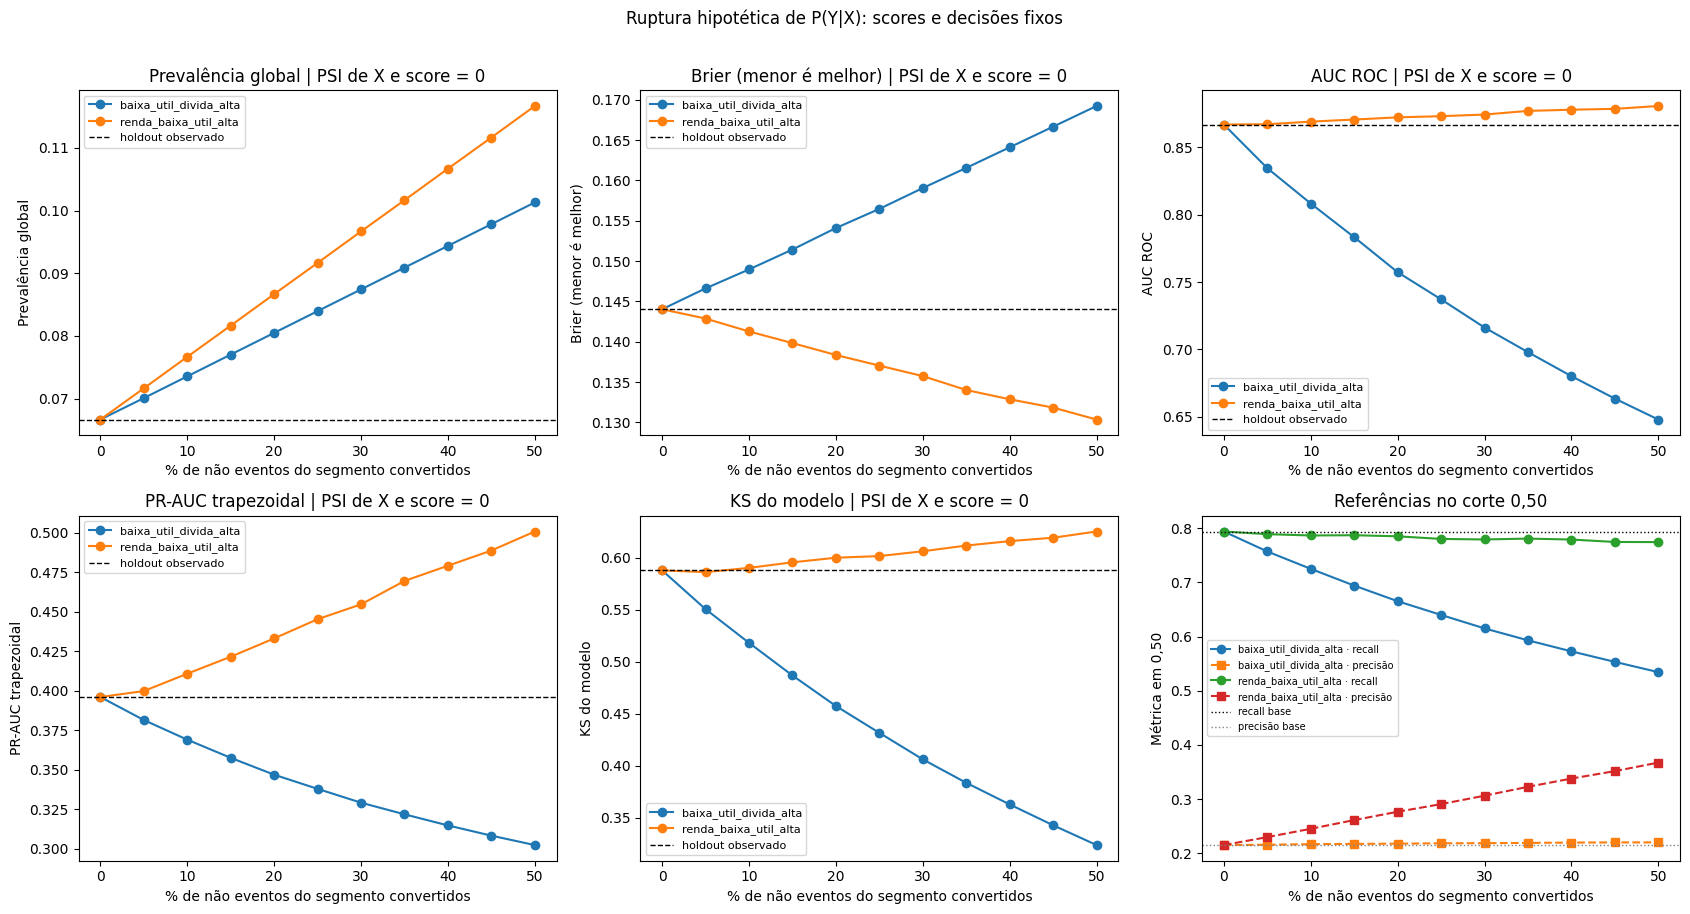

In [4]:
fig, axs = plt.subplots(2,3,figsize=(17,9))
medidas = [('prevalencia','Prevalência global'),('brier','Brier (menor é melhor)'),
           ('auc_roc','AUC ROC'),('pr_auc_trap','PR-AUC trapezoidal'),
           ('ks_modelo','KS do modelo')]
for ax,(col,titulo) in zip(axs.flat[:5],medidas):
    for nome,d in res.groupby('segmento'):
        ax.plot(100*d.fracao_nao_eventos_convertidos,d[col],marker='o',label=nome)
    ax.axhline(base[col],color='black',ls='--',lw=1,label='holdout observado')
    ax.set(xlabel='% de não eventos do segmento convertidos',ylabel=titulo,
           title=titulo+' | PSI de X e score = 0')
    ax.legend(fontsize=8)
ax = axs.flat[5]
for nome,d in res.groupby('segmento'):
    ax.plot(100*d.fracao_nao_eventos_convertidos,d['recall'],marker='o',label=nome+' · recall')
    ax.plot(100*d.fracao_nao_eventos_convertidos,d['precisao'],marker='s',ls='--',label=nome+' · precisão')
ax.axhline(base['recall'],color='black',ls=':',lw=1,label='recall base')
ax.axhline(base['precisao'],color='gray',ls=':',lw=1,label='precisão base')
ax.set(xlabel='% de não eventos do segmento convertidos',ylabel='Métrica em 0,50',
       title='Referências no corte 0,50')
ax.legend(fontsize=7)
fig.suptitle('Ruptura hipotética de P(Y|X): scores e decisões fixos',y=1.01)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'grafico_ruptura_condicional_rotulos.png',dpi=160,bbox_inches='tight')
plt.show()

## 4. Calibração por faixa de score

Com os mesmos scores, a frequência de evento **hipotética** muda nas faixas afetadas. Os decis são definidos pelo score do holdout de referência e permanecem fixos. `observado` abaixo significa o rótulo real do holdout; `hipotético` significa o desfecho artificial do cenário de 50%. A curva não pretende prever qual será a calibração em produção.


,segmento,decil,n,score_medio,taxa_observada,taxa_hipotetica
0,baixa_util_divida_alta,1,2250,0.0599,0.0027,0.1293
1,baixa_util_divida_alta,2,2250,0.0859,0.0080,0.0853
2,baixa_util_divida_alta,3,2250,0.1132,0.0098,0.0520
3,baixa_util_divida_alta,4,2250,0.1474,0.0098,0.0444
4,baixa_util_divida_alta,5,2250,0.1953,0.0160,0.0320
5,baixa_util_divida_alta,6,2250,0.2669,0.0258,0.0396
6,baixa_util_divida_alta,7,2250,0.3674,0.0373,0.0547
7,baixa_util_divida_alta,8,2250,0.4943,0.0724,0.0831
8,baixa_util_divida_alta,9,2250,0.6436,0.1196,0.1253
9,baixa_util_divida_alta,10,2250,0.8660,0.3653,0.3671


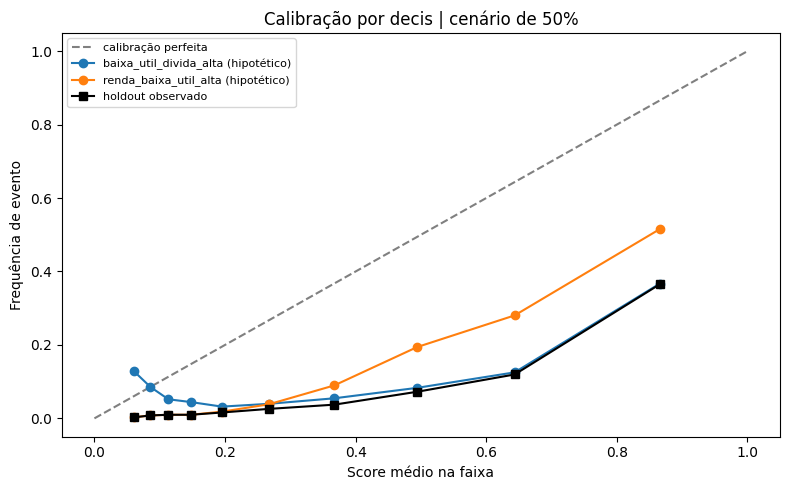

In [5]:
bins = np.unique(np.quantile(p,np.linspace(0,1,11)))
faixa = pd.cut(p,bins=np.r_[-np.inf,bins[1:-1],np.inf],labels=False)
cal = []
for nome, mascara in grupos.items():
    elegiveis = np.flatnonzero(mascara & (y0==0))
    ordem = np.random.default_rng(20260927+list(grupos).index(nome)).permutation(elegiveis)
    yy = y0.copy(); yy[ordem[:int(np.floor(.50*len(elegiveis)))]] = 1
    for d in np.unique(faixa):
        m = faixa==d
        cal.append({'segmento':nome,'decil':int(d)+1,'n':int(m.sum()),
                    'score_medio':float(p[m].mean()),'taxa_observada':float(y0[m].mean()),
                    'taxa_hipotetica':float(yy[m].mean())})
cal = pd.DataFrame(cal)
cal.to_csv(OUT/'calibracao_ruptura_condicional.csv',index=False)
display(cal.round(4))
fig, ax = plt.subplots(figsize=(8,5))
ax.plot([0,1],[0,1],ls='--',color='gray',label='calibração perfeita')
for nome,d in cal.groupby('segmento'):
    ax.plot(d.score_medio,d.taxa_hipotetica,marker='o',label=nome+' (hipotético)')
ax.plot(cal[cal.segmento==list(grupos)[0]].score_medio,
        cal[cal.segmento==list(grupos)[0]].taxa_observada,
        marker='s',color='black',label='holdout observado')
ax.set(xlabel='Score médio na faixa',ylabel='Frequência de evento',
       title='Calibração por decis | cenário de 50%')
ax.legend(fontsize=8); fig.tight_layout()
fig.savefig(FIGURES_DIR / 'grafico_calibracao_ruptura_condicional.png',dpi=160,bbox_inches='tight')
plt.show()

## 5. O que este teste responde e como replicar

1. **Responde:** PSI e score PSI iguais a zero são compatíveis com mudança relevante de $P(Y\mid X)$ e de métricas supervisionadas. Portanto nenhum corte de PSI, isoladamente, garante desempenho.
2. **Não responde:** qual taxa real de inadimplência ocorrerá após um choque de renda/dívida; os novos rótulos são hipotéticos. As taxas de 5%–50% são intensidades do ensaio, não cenários calibrados economicamente.
3. **Para aplicar:** definir segmentos por variáveis disponíveis antes de olhar desfechos futuros; quando os rótulos chegarem, medir AUC ROC, PR-AUC trapezoidal, KS do modelo e Brier por janela e segmento. Mostrar contagens e prevalência, além de recall e precisão em 0,50. Respeitar atraso de maturação do desfecho e incerteza amostral. Guardar todos os níveis sem escolher ponto de parada.
4. **Conceitos:** *concept drift* é mudança em $P(Y\mid X)$; *covariate shift* é mudança em $P(X)$ sob hipótese de $P(Y\mid X)$ estável; *label shift* em sentido estrito supõe mudança em $P(Y)$ com $P(X\mid Y)$ estável. Este caderno implementa somente um **cenário hipotético de concept drift**.
